# Exploratory analysis: what trends, for how long, and where

This notebook looks at the cleaned data in `data/streampulse.duckdb` and sets up the questions for the analysis phase. Each chart is followed by the table it was drawn from.

YouTube data covers trending lists in India, the US and the UK from 2020-08-12 to 2024-04-15. The Netflix catalog is from September 2021. Cleaning decisions are in `reports/data_quality.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from streampulse.database import connect

connection = connect()


def run_query(sql):
    return connection.execute(sql).df()

In [2]:
COUNTRIES = ["IN", "US", "GB"]
COUNTRY_NAMES = {"IN": "India", "US": "United States", "GB": "United Kingdom"}
# Colorblind-checked order. A country keeps its color in every chart.
COUNTRY_COLORS = {"IN": "#2a78d6", "US": "#eb6834", "GB": "#1baf7a"}
SINGLE_SERIES_COLOR = "#2a78d6"
TYPE_COLORS = {"Movie": "#2a78d6", "TV Show": "#eb6834"}
BLUE_RAMP = LinearSegmentedColormap.from_list("blue_ramp", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": "#898781",
    "ytick.color": "#898781",
    "legend.frameon": False,
    "lines.linewidth": 2,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
})

## 1. What trends: category mix by country

Share of each country's trending videos by YouTube category. The eight largest categories overall are shown; the rest are grouped as Other.

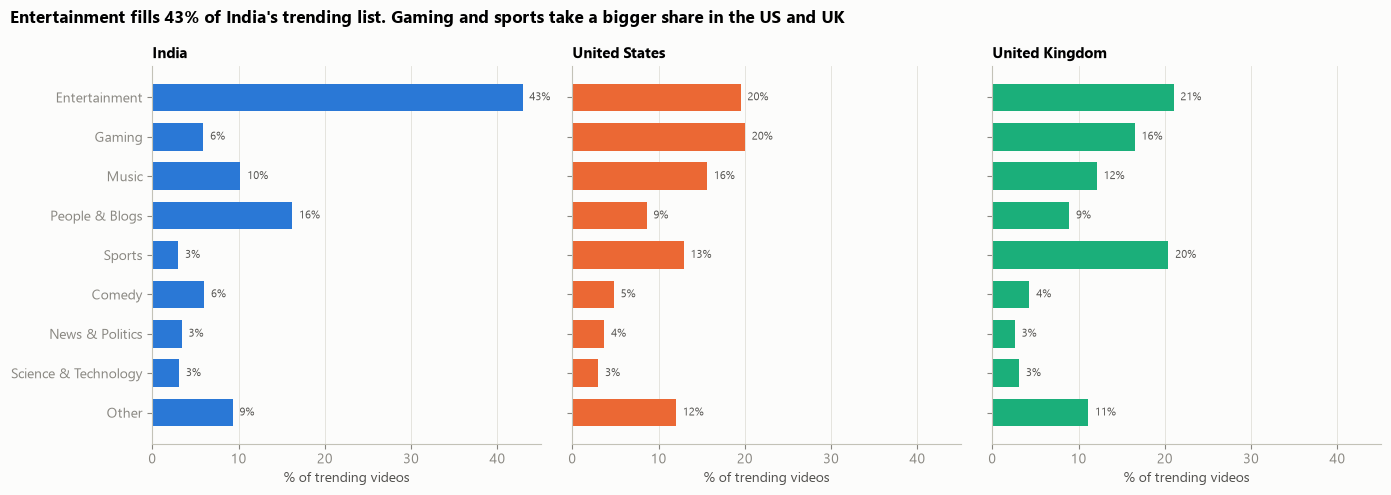

country,IN,US,GB
category,,,
Entertainment,42.9,19.5,21.0
Gaming,5.9,20.0,16.5
Music,10.2,15.6,12.1
People & Blogs,16.2,8.6,8.9
Sports,3.0,12.9,20.4
Comedy,6.0,4.8,4.3
News & Politics,3.4,3.7,2.6
Science & Technology,3.1,3.0,3.1
Other,9.3,12.0,11.1


In [3]:
category_videos = run_query("""
    SELECT country, category, count(*) AS videos
    FROM trending_videos
    GROUP BY country, category
""")
top_categories = category_videos.groupby("category")["videos"].sum().nlargest(8).index
category_videos["category"] = category_videos["category"].where(category_videos["category"].isin(top_categories), "Other")
category_share = (
    category_videos.groupby(["category", "country"])["videos"].sum()
    .groupby(level="country").transform(lambda videos: 100 * videos / videos.sum())
    .unstack("country")[COUNTRIES]
    .round(1)
)
category_order = list(top_categories[::-1])
category_order.insert(0, "Other")
category_share = category_share.loc[category_order]

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, sharex=True)
for ax, country in zip(axes, COUNTRIES):
    ax.barh(category_share.index, category_share[country], color=COUNTRY_COLORS[country], height=0.7)
    for y_position, share in enumerate(category_share[country]):
        ax.text(share + 0.8, y_position, f"{share:.0f}%", va="center", fontsize=8, color="#52514e")
    ax.set_title(COUNTRY_NAMES[country], fontsize=11)
    ax.set_xlabel("% of trending videos")
    ax.grid(axis="y", visible=False)
fig.suptitle("Entertainment fills 43% of India's trending list. Gaming and sports take a bigger share in the US and UK",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

category_share.iloc[::-1]

## 2. How long videos stay on the list

Days on the trending list per video. Videos already trending on the first day of the data, or still trending on the last day, are left out because their runs are cut off by the dataset window. The analysis phase keeps them using survival analysis.

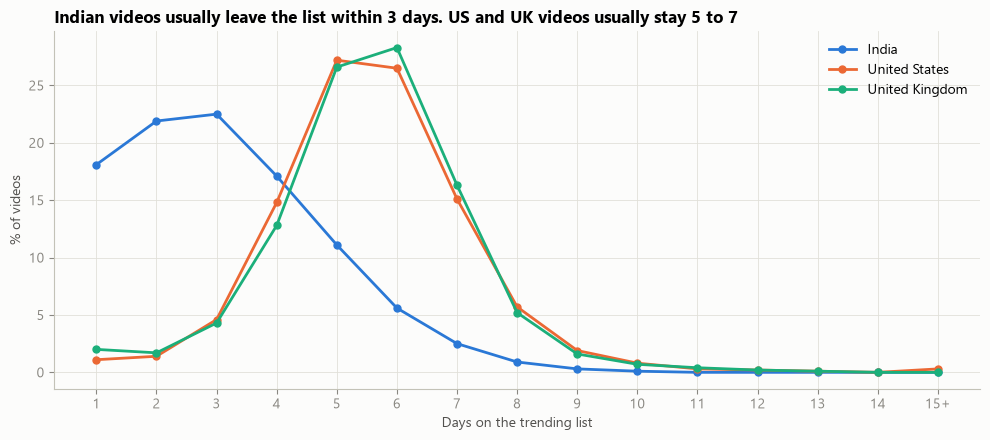

days_trending,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,median_days
country,,,,,,,,,,,,,,,,
IN,18.1,21.9,22.5,17.1,11.1,5.6,2.5,0.9,0.3,0.1,0.0,0.0,0.0,0.0,0.0,3.0
US,1.1,1.4,4.6,14.8,27.2,26.5,15.1,5.7,1.9,0.8,0.3,0.2,0.1,0.0,0.3,6.0
GB,2.0,1.7,4.3,12.8,26.6,28.3,16.3,5.2,1.6,0.7,0.4,0.2,0.1,0.0,0.0,6.0


In [4]:
trending_duration = run_query("""
    SELECT country, least(days_trending, 15) AS days_trending, count(*) AS videos
    FROM trending_videos
    WHERE first_trending_date > DATE '2020-08-12' AND last_trending_date < DATE '2024-04-15'
    GROUP BY country, least(days_trending, 15)
""")
duration_share = (
    trending_duration.pivot(index="days_trending", columns="country", values="videos")[COUNTRIES]
    .fillna(0)
    .pipe(lambda counts: 100 * counts / counts.sum())
    .round(1)
)

fig, ax = plt.subplots(figsize=(10, 4.5))
for country in COUNTRIES:
    ax.plot(duration_share.index, duration_share[country], marker="o", markersize=5,
            color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_xticks(range(1, 16), [str(day) for day in range(1, 15)] + ["15+"])
ax.set_xlabel("Days on the trending list")
ax.set_ylabel("% of videos")
ax.set_title("Indian videos usually leave the list within 3 days. US and UK videos usually stay 5 to 7")
ax.legend()
plt.tight_layout()
plt.show()

duration_share.T.assign(
    median_days=run_query("""
        SELECT country, median(days_trending) AS median_days FROM trending_videos
        WHERE first_trending_date > DATE '2020-08-12' AND last_trending_date < DATE '2024-04-15'
        GROUP BY country
    """).set_index("country")["median_days"]
)

## 3. How fast videos reach the list

Days between the upload date (UTC) and the first day on a country's trending list. Videos first seen on the first day of the data are left out, since they may have started trending earlier.

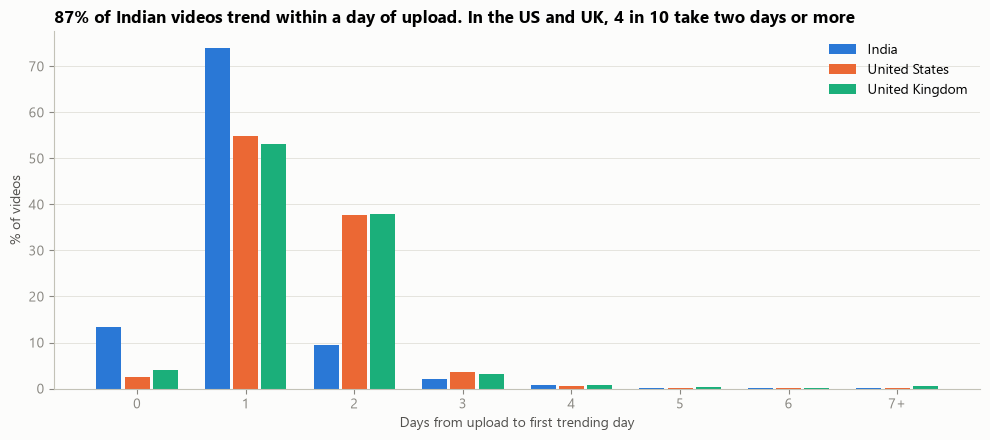

days_to_trend,0,1,2,3,4,5,6,7
country,,,,,,,,
IN,13.4,73.9,9.4,2.1,0.7,0.2,0.1,0.1
US,2.6,54.8,37.8,3.6,0.6,0.2,0.1,0.2
GB,4.0,53.2,37.9,3.1,0.7,0.3,0.2,0.6


In [5]:
days_to_trend = run_query("""
    SELECT
        country,
        least(date_diff('day', CAST(published_at AS DATE), first_trending_date), 7) AS days_to_trend,
        count(*) AS videos
    FROM trending_videos
    WHERE first_trending_date > DATE '2020-08-12'
    GROUP BY ALL
""")
days_to_trend_share = (
    days_to_trend.pivot(index="days_to_trend", columns="country", values="videos")[COUNTRIES]
    .fillna(0)
    .pipe(lambda counts: 100 * counts / counts.sum())
    .round(1)
)

bar_width = 0.26
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, country in zip([-bar_width, 0, bar_width], COUNTRIES):
    ax.bar(days_to_trend_share.index + offset, days_to_trend_share[country], width=bar_width - 0.03,
           color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_xticks(range(0, 8), [str(day) for day in range(0, 7)] + ["7+"])
ax.set_xlabel("Days from upload to first trending day")
ax.set_ylabel("% of videos")
ax.set_title("87% of Indian videos trend within a day of upload. In the US and UK, 4 in 10 take two days or more")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

days_to_trend_share.T

## 4. How quickly each list turns over

New videos entering the trending list per day, averaged by month. A list that keeps the same videos for days needs fewer new entries.

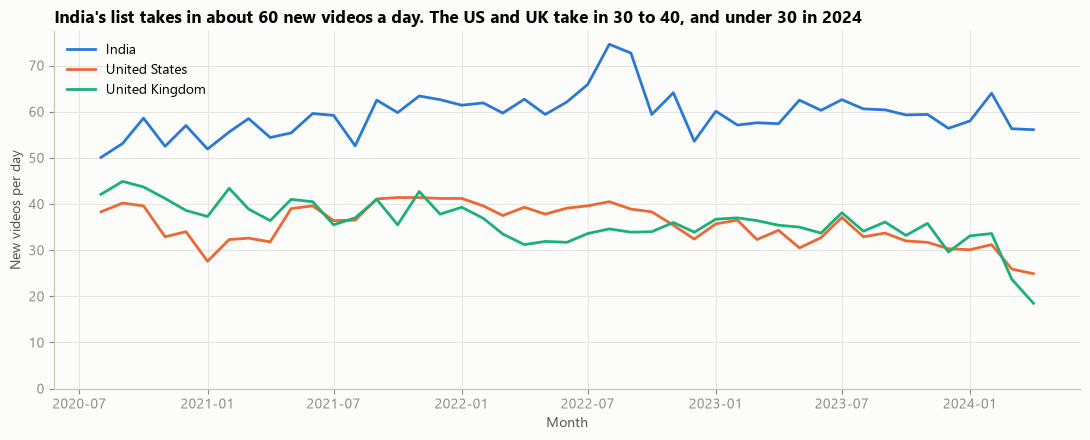

country,IN,US,GB
month,,,
2020,54.3,37.0,42.1
2021,58.0,36.7,38.9
2022,63.1,38.3,34.2
2023,59.5,33.3,35.1
2024,58.6,28.0,27.2


In [6]:
new_videos_per_day = run_query("""
    SELECT
        country,
        date_trunc('month', first_trending_date) AS month,
        count(*) / count(DISTINCT first_trending_date) AS new_videos_per_day
    FROM trending_videos
    WHERE first_trending_date > DATE '2020-08-12'
    GROUP BY ALL
""").pivot(index="month", columns="country", values="new_videos_per_day")[COUNTRIES].round(1)

fig, ax = plt.subplots(figsize=(11, 4.5))
for country in COUNTRIES:
    ax.plot(new_videos_per_day.index, new_videos_per_day[country], color=COUNTRY_COLORS[country],
            label=COUNTRY_NAMES[country])
ax.set_ylim(0, None)
ax.set_xlabel("Month")
ax.set_ylabel("New videos per day")
ax.set_title("India's list takes in about 60 new videos a day. The US and UK take in 30 to 40, and under 30 in 2024")
ax.legend()
plt.tight_layout()
plt.show()

new_videos_per_day.groupby(new_videos_per_day.index.year).mean().round(1)

## 5. Engagement by category

Likes and comments per 1,000 views, measured on each video's peak-views day, all three countries together. Videos with ratings or comments turned off are left out of that measure, not counted as zero. Categories with at least 500 videos.

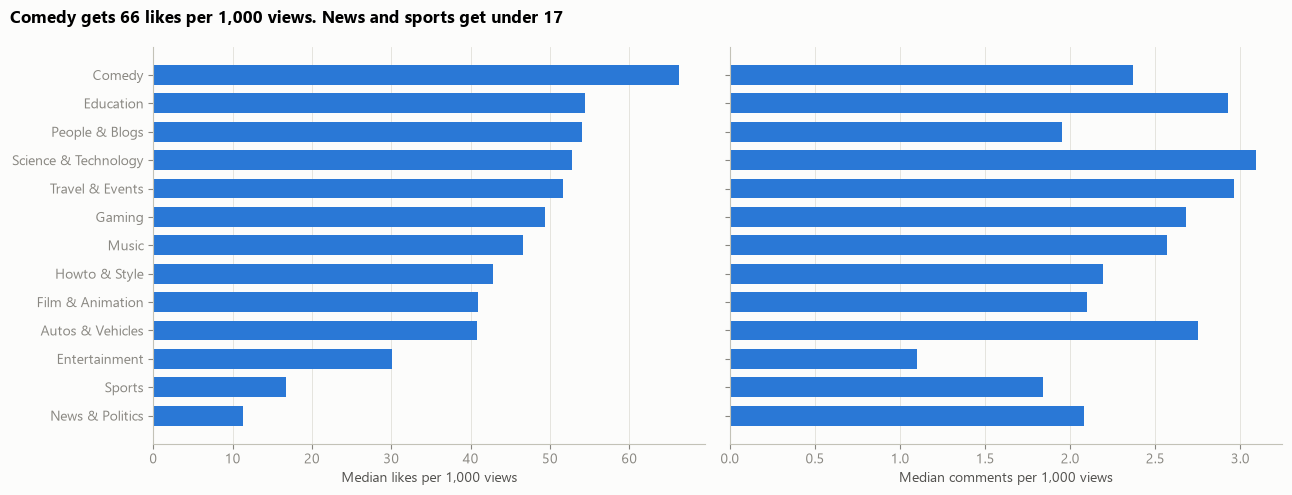

,videos,likes_per_1k_views,comments_per_1k_views
category,,,
Comedy,9064,66.28,2.37
Education,4390,54.38,2.93
People & Blogs,20999,54.03,1.95
Science & Technology,5387,52.76,3.09
Travel & Events,1315,51.59,2.96
Gaming,21954,49.37,2.68
Music,21088,46.54,2.57
Howto & Style,4674,42.82,2.19
Film & Animation,4780,40.98,2.10


In [7]:
category_engagement = run_query("""
    SELECT
        category,
        count(*) AS videos,
        median(1000.0 * likes_at_peak / peak_views) AS likes_per_1k_views,
        median(1000.0 * comments_at_peak / peak_views) AS comments_per_1k_views
    FROM trending_videos
    WHERE peak_views > 0
    GROUP BY category
    HAVING count(*) >= 500
""").sort_values("likes_per_1k_views").set_index("category").round(2)

fig, (likes_ax, comments_ax) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
likes_ax.barh(category_engagement.index, category_engagement["likes_per_1k_views"], color=SINGLE_SERIES_COLOR, height=0.7)
likes_ax.set_xlabel("Median likes per 1,000 views")
comments_ax.barh(category_engagement.index, category_engagement["comments_per_1k_views"], color=SINGLE_SERIES_COLOR, height=0.7)
comments_ax.set_xlabel("Median comments per 1,000 views")
for ax in (likes_ax, comments_ax):
    ax.grid(axis="y", visible=False)
fig.suptitle("Comedy gets 66 likes per 1,000 views. News and sports get under 17", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

category_engagement.iloc[::-1]

## 6. How many views a trending video gets

Peak views per video on a log scale. The spread is wide enough that averages would mislead, so the analysis uses medians.

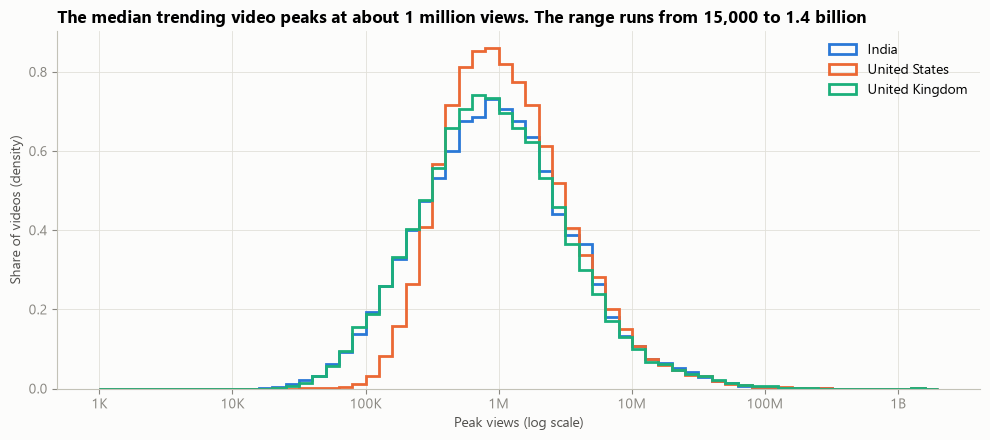

,count,mean,std,min,10%,50%,90%,max
country,,,,,,,,
IN,78844.0,2458200.0,6176333.0,15555.0,182055.0,928364.0,5008450.0,2.644074e+08
US,47124.0,2670554.0,9626089.0,22253.0,322187.0,1067672.0,5173376.0,1.407644e+09
GB,47591.0,2474162.0,9314733.0,21185.0,181498.0,875266.0,4770063.0,1.406330e+09


In [8]:
peak_views = run_query("""
    SELECT country, peak_views FROM trending_videos WHERE peak_views > 0
""")
log_bins = np.linspace(3, 9.3, 64)

fig, ax = plt.subplots(figsize=(10, 4.5))
for country in COUNTRIES:
    country_views = peak_views.loc[peak_views["country"] == country, "peak_views"]
    ax.hist(np.log10(country_views), bins=log_bins, density=True, histtype="step", linewidth=2,
            color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_xticks([3, 4, 5, 6, 7, 8, 9], ["1K", "10K", "100K", "1M", "10M", "100M", "1B"])
ax.set_xlabel("Peak views (log scale)")
ax.set_ylabel("Share of videos (density)")
ax.set_title("The median trending video peaks at about 1 million views. The range runs from 15,000 to 1.4 billion")
ax.legend()
plt.tight_layout()
plt.show()

peak_views.groupby("country")["peak_views"].describe(percentiles=[0.1, 0.5, 0.9]).loc[COUNTRIES].round(0)

## 7. When trending videos were published

Share of each country's trending videos by day of week and hour of upload, in local time (India IST, UK London time, US Eastern time). All three panels share one color scale. This shows when trending videos were uploaded, not whether a time slot helps a video trend: that needs a comparison with videos that did not trend, which this data does not have.

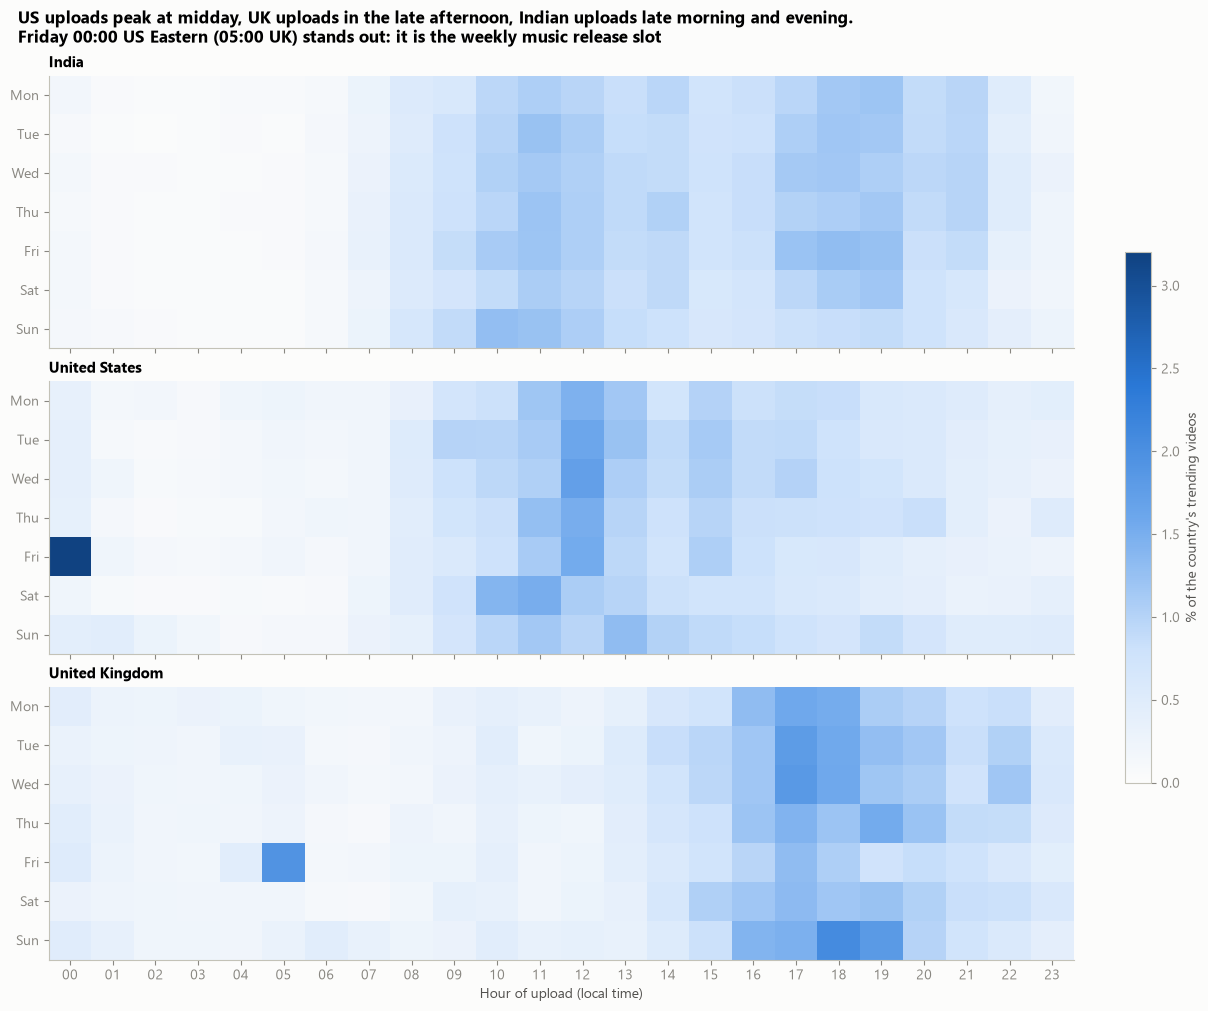

,country,weekday,hour,videos,pct_of_country
0,GB,Sun,18,986,2.07
1,GB,Fri,5,917,1.93
2,GB,Wed,17,873,1.83
3,GB,Sun,19,866,1.82
4,GB,Tue,17,848,1.78
5,IN,Fri,18,1024,1.30
6,IN,Sun,10,1009,1.28
7,IN,Fri,19,985,1.25
8,IN,Tue,11,973,1.23
9,IN,Sun,11,969,1.23


In [9]:
publish_slots = run_query("""
    WITH local_publish AS (
        SELECT
            country,
            timezone(
                CASE country WHEN 'IN' THEN 'Asia/Kolkata' WHEN 'US' THEN 'America/New_York' ELSE 'Europe/London' END,
                published_at AT TIME ZONE 'UTC'
            ) AS published_local
        FROM trending_videos
    )
    SELECT country, isodow(published_local) AS weekday, hour(published_local) AS hour, count(*) AS videos
    FROM local_publish
    GROUP BY ALL
""")
publish_slots["pct_of_country"] = 100 * publish_slots["videos"] / publish_slots.groupby("country")["videos"].transform("sum")
color_scale_max = publish_slots["pct_of_country"].max()
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, layout="constrained")
for ax, country in zip(axes, COUNTRIES):
    weekday_hour_grid = (
        publish_slots[publish_slots["country"] == country]
        .pivot(index="weekday", columns="hour", values="pct_of_country")
        .reindex(index=range(1, 8), columns=range(24))
        .fillna(0)
    )
    heatmap = ax.imshow(weekday_hour_grid, cmap=BLUE_RAMP, aspect="auto", vmin=0, vmax=color_scale_max)
    ax.set_yticks(range(7), weekday_labels)
    ax.set_title(COUNTRY_NAMES[country], fontsize=11)
    ax.grid(False)
axes[-1].set_xticks(range(24), [f"{hour:02d}" for hour in range(24)])
axes[-1].set_xlabel("Hour of upload (local time)")
fig.colorbar(heatmap, ax=axes, label="% of the country's trending videos", shrink=0.6)
fig.suptitle("US uploads peak at midday, UK uploads in the late afternoon, Indian uploads late morning and evening.\nFriday 00:00 US Eastern (05:00 UK) stands out: it is the weekly music release slot",
             x=0.01, ha="left", fontweight="bold")
plt.show()

(
    publish_slots.assign(weekday=publish_slots["weekday"].map(dict(enumerate(weekday_labels, start=1))))
    .sort_values("pct_of_country", ascending=False)
    .groupby("country").head(5)
    .sort_values(["country", "pct_of_country"], ascending=[True, False])
    .round(2)
    .reset_index(drop=True)
)

In [10]:
run_query("""
    SELECT category, count(*) AS videos
    FROM trending_videos
    WHERE country = 'US'
      AND dayname(timezone('America/New_York', published_at AT TIME ZONE 'UTC')) = 'Friday'
      AND hour(timezone('America/New_York', published_at AT TIME ZONE 'UTC')) = 0
    GROUP BY category
    ORDER BY videos DESC
    LIMIT 5
""")

,category,videos
0,Music,1334
1,Entertainment,60
2,People & Blogs,48
3,Sports,34
4,Gaming,13


## 8. Overlap between countries

Each video is counted once, under the set of countries where it trended.

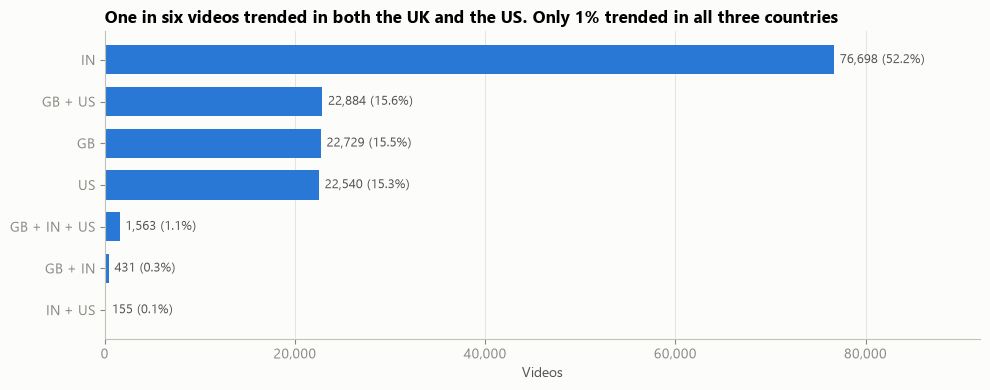

,videos,pct_of_videos
countries,,
IN,76698,52.2
GB + US,22884,15.6
GB,22729,15.5
US,22540,15.3
GB + IN + US,1563,1.1
GB + IN,431,0.3
IN + US,155,0.1


In [11]:
country_overlap = run_query("""
    WITH video_countries AS (
        SELECT video_id, string_agg(country, ' + ' ORDER BY country) AS countries
        FROM trending_videos
        GROUP BY video_id
    )
    SELECT countries, count(*) AS videos, round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct_of_videos
    FROM video_countries
    GROUP BY countries
    ORDER BY videos
""").set_index("countries")

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(country_overlap.index, country_overlap["videos"], color=SINGLE_SERIES_COLOR, height=0.7)
for y_position, (videos, pct) in enumerate(zip(country_overlap["videos"], country_overlap["pct_of_videos"])):
    ax.text(videos + 600, y_position, f"{videos:,} ({pct}%)", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Videos")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.set_xlim(0, country_overlap["videos"].max() * 1.2)
ax.grid(axis="y", visible=False)
ax.set_title("One in six videos trended in both the UK and the US. Only 1% trended in all three countries")
plt.tight_layout()
plt.show()

country_overlap.iloc[::-1]

## 9. Netflix catalog growth

Titles added per year by type. Only 56 titles were added from 2008 to 2014, so the chart starts in 2015. 2021 runs only to 25 September.

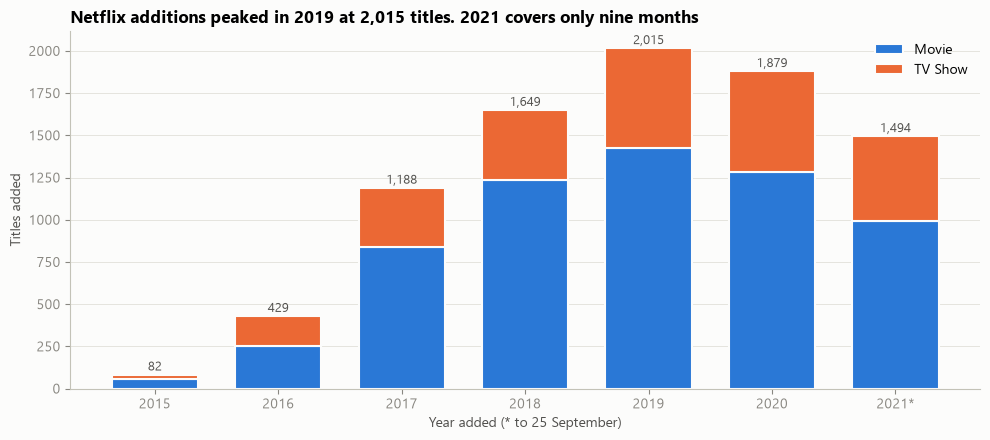

type,Movie,TV Show,total
year_added,,,
2008,1,1,2
2009,2,0,2
2010,1,0,1
2011,13,0,13
2012,3,0,3
2013,6,5,11
2014,19,5,24
2015,56,26,82
2016,253,176,429


In [12]:
titles_added = run_query("""
    SELECT year(date_added) AS year_added, type, count(*) AS titles
    FROM netflix_titles
    WHERE date_added IS NOT NULL
    GROUP BY ALL
""").pivot(index="year_added", columns="type", values="titles").fillna(0).astype(int)
recent_titles_added = titles_added.loc[2015:]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(recent_titles_added.index, recent_titles_added["Movie"], color=TYPE_COLORS["Movie"], width=0.7,
       label="Movie", edgecolor=SURFACE, linewidth=1.5)
ax.bar(recent_titles_added.index, recent_titles_added["TV Show"], bottom=recent_titles_added["Movie"],
       color=TYPE_COLORS["TV Show"], width=0.7, label="TV Show", edgecolor=SURFACE, linewidth=1.5)
for year, total in recent_titles_added.sum(axis=1).items():
    ax.text(year, total + 25, f"{total:,}", ha="center", fontsize=9, color="#52514e")
ax.set_xticks(recent_titles_added.index, [str(year) if year < 2021 else "2021*" for year in recent_titles_added.index])
ax.set_xlabel("Year added (* to 25 September)")
ax.set_ylabel("Titles added")
ax.grid(axis="x", visible=False)
ax.set_title("Netflix additions peaked in 2019 at 2,015 titles. 2021 covers only nine months")
ax.legend()
plt.tight_layout()
plt.show()

titles_added.assign(total=titles_added.sum(axis=1))

## 10. How Netflix titles rate on IMDb

IMDb rating distribution for matched titles with at least 1,000 votes. Fewer votes make a rating noisy. Ratings are from the October 2026 IMDb snapshot.

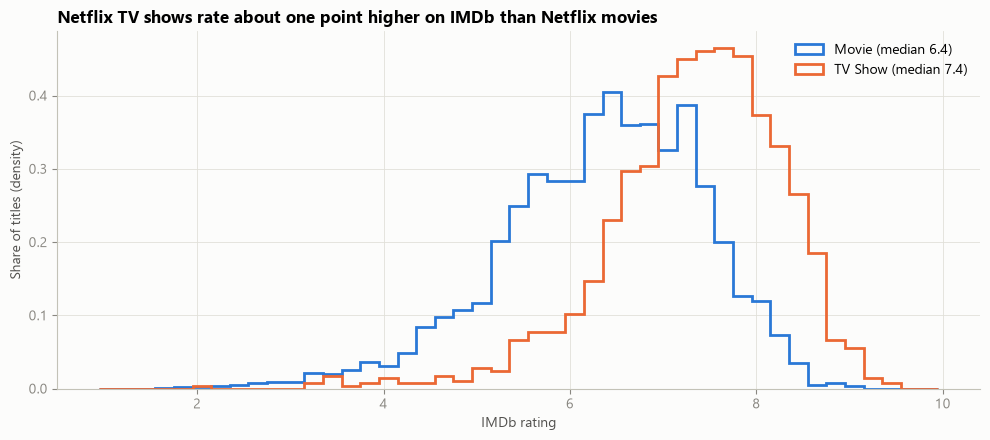

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,3659.0,6.34,1.09,1.7,5.7,6.4,7.1,9.1
TV Show,1432.0,7.33,0.94,2.0,6.8,7.4,8.0,9.5


In [13]:
rated_titles = run_query("""
    SELECT type, imdb_rating FROM netflix_titles WHERE imdb_votes >= 1000
""")
# Ratings come in steps of 0.1. Bins of 0.2 centred between steps hold exactly two rating values each,
# which avoids the comb pattern that uneven bins produce.
rating_bins = np.arange(0.95, 10.06, 0.2)

fig, ax = plt.subplots(figsize=(10, 4.5))
for title_type, type_ratings in rated_titles.groupby("type")["imdb_rating"]:
    ax.hist(type_ratings, bins=rating_bins, density=True, histtype="step", linewidth=2,
            color=TYPE_COLORS[title_type], label=f"{title_type} (median {type_ratings.median():.1f})")
ax.set_xlabel("IMDb rating")
ax.set_ylabel("Share of titles (density)")
ax.set_title("Netflix TV shows rate about one point higher on IMDb than Netflix movies")
ax.legend()
plt.tight_layout()
plt.show()

rated_titles.groupby("type")["imdb_rating"].describe().round(2)

## What this suggests, and what it does not show yet

**What the data suggests**

- **India's trending list works differently.** Videos stay a median of 3 days (6 in the US and UK), about 60 new videos enter each day (30 to 40 in the US and UK), and 87% of videos trend within a day of upload (57% in the US and UK).
- **Category mix differs by country.** Entertainment is 43% of India's trending videos. Gaming (20% US, 17% UK) and sports (13% US, 20% UK) are far bigger in the US and UK than in India (6% and 3%).
- **Engagement varies about sixfold by category**, from 66 likes per 1,000 views for Comedy to 11 for News & Politics. Engagement comparisons have to be made within a category.
- **Upload times differ by country.** The US peaks at midday Eastern time, the UK in the late afternoon, India in the late morning and early evening. The single biggest US slot, Friday 00:00 Eastern, is 88% Music (1,334 of 1,509 videos): the weekly music release time. The same releases show up in the UK at Friday 05:00.
- **The UK and US share a lot, India very little.** 16.7% of all videos trended in both the UK and the US (15.6% in only those two, 1.1% in all three). 52% of all videos trended only in India.
- **Netflix** additions peaked in 2019 at 2,015 titles. Among titles with at least 1,000 IMDb votes, TV shows have a median rating of 7.4 against 6.4 for movies.

**What this does not show yet**

- Nothing here is tested statistically. Small categories in particular may differ by chance.
- Upload-time charts describe videos that trended. The data has no videos that failed to trend, so they cannot say whether a time slot helps.
- Trending duration leaves out runs cut off by the dataset window. Survival analysis can include them.
- The TV versus movie rating gap may come from which titles collect 1,000 votes rather than from quality.

**Questions for the analysis phase**

1. Do trending durations differ significantly between categories and countries once cut-off runs are included (Kaplan-Meier curves and log-rank tests)?
2. Is India's shorter trending life explained by its category mix, or does it hold within the same category?
3. Are the differences in engagement between categories larger than chance?
4. Do publish-time patterns hold within categories once the Friday music releases are separated out?
5. How concentrated are the lists among channels (Lorenz curve and Gini coefficient)?